In [2]:
import pandas as pd
import yfinance as yf
import requests
from io import StringIO

url = "https://www.niftyindices.com/IndexConstituent/ind_nifty100list.csv"

headers = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "text/csv,application/csv,text/plain,*/*",
    "Referer": "https://www.niftyindices.com/"
}

response = requests.get(
    url,
    headers=headers,
    timeout=30
)

response.raise_for_status()

nifty100 = pd.read_csv(StringIO(response.text))

print(nifty100[["Company Name", "Symbol"]])
print("Number of companies:", len(nifty100))

tickers = [symbol + ".NS" for symbol in nifty100["Symbol"]]

print(tickers)

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-10-06",
    group_by="ticker",
    auto_adjust=True,
    threads=True
)

print(data.head())

                                  Company Name      Symbol
0                               ABB India Ltd.         ABB
1                  Adani Energy Solutions Ltd.  ADANIENSOL
2                       Adani Enterprises Ltd.    ADANIENT
3                      Adani Green Energy Ltd.  ADANIGREEN
4   Adani Ports and Special Economic Zone Ltd.  ADANIPORTS
..                                         ...         ...
95                Vedanta Aluminium Metal Ltd.        VAML
96                                Vedanta Ltd.        VEDL
97                          Vodafone Idea Ltd.        IDEA
98                                  Wipro Ltd.       WIPRO
99                     Zydus Lifesciences Ltd.   ZYDUSLIFE

[100 rows x 2 columns]
Number of companies: 100
['ABB.NS', 'ADANIENSOL.NS', 'ADANIENT.NS', 'ADANIGREEN.NS', 'ADANIPORTS.NS', 'ADANIPOWER.NS', 'AMBUJACEM.NS', 'APOLLOHOSP.NS', 'ASIANPAINT.NS', 'DMART.NS', 'AXISBANK.NS', 'BSE.NS', 'BAJAJ-AUTO.NS', 'BAJFINANCE.NS', 'BAJAJFINSV.NS', 'BAJAJHLDNG

[*********************100%***********************]  100 of 100 completed

Ticker        NTPC.NS                                           VAML.NS       \
Price            Open       High        Low      Close   Volume    Open High   
Date                                                                           
2020-01-01  91.791271  94.065811  91.174444  93.718849  9953746     NaN  NaN   
2020-01-02  93.680305  94.181476  92.986375  93.603203  8731299     NaN  NaN   
2020-01-03  93.294794  93.564653  91.829833  92.022591  7392962     NaN  NaN   
2020-01-06  91.752738  91.868394  89.825160  91.675636  6596841     NaN  NaN   
2020-01-07  91.945480  93.718854  91.945480  92.947823  8959942     NaN  NaN   

Ticker                       ...      ITC.NS                          \
Price      Low Close Volume  ...        Open        High         Low   
Date                         ...                                       
2020-01-01 NaN   NaN    NaN  ...  169.151118  169.151118  168.087725   
2020-01-02 NaN   NaN    NaN  ...  168.867528  170.817096  168.796641   

In [3]:
import pandas

fields = ["Open","High","Low","Close","Volume"]
panels = {f.lower(): data.xs(f, axis=1, level="Price") for f in fields}

close = panels["close"]
close

Ticker,NTPC.NS,VAML.NS,MAXHEALTH.NS,ICICIBANK.NS,BANKBARODA.NS,BOSCHLTD.NS,VEDL.NS,SHRIRAMFIN.NS,BAJAJHLDNG.NS,IDEA.NS,...,LT.NS,BPCL.NS,BRITANNIA.NS,DRREDDY.NS,MARUTI.NS,INFY.NS,PFC.NS,HCLTECH.NS,ITC.NS,COALINDIA.NS
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,93.718849,NaN,NaN,514.797974,87.505669,14021.473633,65.055290,200.681625,3016.526367,6.10,...,1180.674561,157.650101,2671.135986,550.994202,6876.276367,619.740356,58.647854,446.139526,168.796661,113.782066
2020-01-02,93.603203,NaN,NaN,518.490417,89.695450,14138.021484,67.096161,203.843506,3103.626953,6.10,...,1212.536133,156.335403,2683.219238,548.219421,6893.345703,617.932068,59.366108,447.387512,170.037262,113.325752
2020-01-03,92.022591,NaN,NaN,516.812012,86.603996,13918.824219,66.380814,203.746872,3097.686523,6.10,...,1203.297607,155.036743,2670.389160,551.855347,6822.247070,627.436157,58.821236,456.357910,169.080185,113.728386
2020-01-06,91.675636,NaN,NaN,504.199890,82.267349,13593.988281,63.351082,196.228714,3082.053223,6.00,...,1186.803467,150.435333,2655.670166,550.888855,6623.013184,621.422363,55.923508,453.978729,166.669830,110.426849
2020-01-07,92.947823,NaN,NaN,501.514343,82.567917,13602.428711,65.644417,197.484634,3034.348633,6.00,...,1190.183472,147.822021,2668.456055,551.912659,6652.355469,612.212891,57.929623,455.733795,166.847046,110.426849
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-29,323.500000,434.450012,982.099976,1292.199951,227.679993,45700.000000,260.000000,971.500000,10600.000000,13.56,...,3749.100098,299.350006,4835.000000,1251.900024,11877.000000,1015.400024,324.100006,1222.000000,265.100006,425.000000
2026-09-30,322.750000,412.899994,929.799988,1321.699951,230.550003,47100.000000,259.000000,982.700012,10788.000000,12.95,...,3760.000000,303.200012,4830.000000,1233.000000,11967.000000,994.099976,325.500000,1230.000000,262.750000,425.000000
2026-10-01,315.100006,402.750000,940.950012,1310.599976,230.820007,45480.000000,252.050003,945.000000,10666.000000,12.64,...,3693.399902,300.600006,4778.000000,1206.199951,11386.000000,1035.000000,318.000000,1243.099976,255.899994,420.399994


In [4]:
complete = close.dropna(axis=1, how="any").dropna(axis=0, how="any")

print("tickers:", close.shape[1], "->", complete.shape[1])
print("dates:  ", close.shape[0], "->", complete.shape[0])
print("dropped tickers:", sorted(set(close.columns) - set(complete.columns)))

panels = {n: p.loc[complete.index, complete.columns] for n, p in panels.items()}
open_, high, low, close, volume = (
    panels[n] for n in ["open", "high", "low", "close", "volume"]
)

assert not any(p.isna().any().any() for p in panels.values()), "NaNs remain"
open_


tickers: 100 -> 80
dates:   1679 -> 1679
dropped tickers: ['BAJAJHLDNG.NS', 'BOSCHLTD.NS', 'DIVISLAB.NS', 'ENRIN.NS', 'ETERNAL.NS', 'GRASIM.NS', 'HYUNDAI.NS', 'INDIGO.NS', 'IRFC.NS', 'JIOFIN.NS', 'MAXHEALTH.NS', 'MAZDOCK.NS', 'NESTLEIND.NS', 'POWERINDIA.NS', 'SIEMENS.NS', 'SOLARINDS.NS', 'TATACAP.NS', 'TMCV.NS', 'VAML.NS', 'ZYDUSLIFE.NS']


Ticker,NTPC.NS,ICICIBANK.NS,BANKBARODA.NS,VEDL.NS,SHRIRAMFIN.NS,IDEA.NS,SBILIFE.NS,TITAN.NS,TMPV.NS,BHARTIARTL.NS,...,LT.NS,BPCL.NS,BRITANNIA.NS,DRREDDY.NS,MARUTI.NS,INFY.NS,PFC.NS,HCLTECH.NS,ITC.NS,COALINDIA.NS
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,91.791271,517.819168,87.806227,64.297854,206.346627,6.20,953.371564,1167.814800,180.379027,430.526963,...,1179.277592,157.762332,2675.573789,551.109011,6937.687461,618.184403,58.276352,444.150453,169.151118,113.459971
2020-01-02,93.680305,514.078573,87.677411,65.349854,201.129582,6.00,963.942584,1131.200104,180.232902,428.686097,...,1182.522373,157.505802,2677.595232,551.836102,6891.229694,621.464560,58.796472,446.607480,168.867528,114.077317
2020-01-03,93.294794,515.996799,89.266091,66.654329,203.746872,6.10,958.311334,1130.222340,187.929326,430.196533,...,1212.220515,155.165003,2675.837456,548.219511,6892.498742,617.259264,59.217505,447.738562,170.852514,112.735239
2020-01-06,91.752738,515.277506,85.831117,66.023143,202.218695,6.05,954.458271,1136.088612,186.078281,428.497239,...,1199.647172,152.311167,2662.656301,549.386694,6771.227931,627.520099,58.102987,456.318826,168.371261,112.708396
2020-01-07,91.945480,509.570763,83.813088,64.297866,197.010366,6.00,978.070381,1144.838816,182.181364,426.703583,...,1196.943317,150.034540,2666.083219,553.022505,6677.183213,620.707650,56.468379,453.978723,167.343299,110.856319
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-29,320.500000,1295.699951,227.500000,259.000000,975.000000,13.60,1731.599976,4808.000000,279.000000,1764.000000,...,3768.000000,302.250000,4899.000000,1243.199951,12046.000000,1002.599976,330.250000,1252.599976,265.450012,420.549988
2026-09-30,323.500000,1295.300049,230.399994,260.000000,972.200012,13.60,1724.000000,4683.000000,281.000000,1775.199951,...,3756.199951,301.950012,4830.000000,1242.199951,11901.000000,1004.000000,325.850006,1229.000000,265.000000,425.100006
2026-10-01,320.799988,1316.000000,230.000000,256.350006,973.500000,12.95,1676.300049,4574.899902,280.000000,1745.000000,...,3726.000000,302.000000,4798.000000,1233.000000,11900.000000,1010.000000,325.850006,1230.000000,262.700012,421.200012


In [5]:
returns = close.pct_change(fill_method=None)
returns

Ticker,NTPC.NS,ICICIBANK.NS,BANKBARODA.NS,VEDL.NS,SHRIRAMFIN.NS,IDEA.NS,SBILIFE.NS,TITAN.NS,TMPV.NS,BHARTIARTL.NS,...,LT.NS,BPCL.NS,BRITANNIA.NS,DRREDDY.NS,MARUTI.NS,INFY.NS,PFC.NS,HCLTECH.NS,ITC.NS,COALINDIA.NS
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,-0.001234,0.007173,0.025024,0.031371,0.015756,0.000000,-0.007221,0.000736,0.050420,0.004191,...,0.026986,-0.008339,0.004524,-0.005036,0.002482,-0.002918,0.012247,0.002797,0.007350,-0.004010
2020-01-03,-0.016886,-0.003237,-0.034466,-0.010662,-0.000474,0.000000,0.005932,-0.013759,-0.013677,-0.000220,...,-0.007619,-0.008307,-0.004782,0.006632,-0.010314,0.015380,-0.009178,0.020051,-0.005629,0.003553
2020-01-06,-0.003770,-0.024404,-0.050074,-0.045642,-0.036900,-0.016393,0.008204,0.016583,-0.028519,-0.011975,...,-0.013707,-0.029679,-0.005512,-0.001751,-0.029204,-0.009585,-0.049263,-0.005213,-0.014256,-0.029030
2020-01-07,0.013877,-0.005326,0.003654,0.036200,0.006400,0.000000,0.001831,0.001165,-0.005117,-0.010119,...,0.002848,-0.017372,0.004815,0.001858,0.004430,-0.014820,0.035872,0.003866,0.001063,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-29,0.007474,-0.007527,0.000791,0.003861,-0.004917,0.006682,0.003993,-0.029982,-0.002839,-0.000113,...,-0.004593,-0.009595,-0.016277,0.025307,-0.010909,0.012161,-0.017879,-0.024429,-0.000377,0.005917
2026-09-30,-0.002318,0.022829,0.012605,-0.003846,0.011529,-0.044985,-0.022248,-0.018824,0.009076,-0.008017,...,0.002907,0.012861,-0.001034,-0.015097,0.007578,-0.020977,0.004320,0.006547,-0.008865,0.000000
2026-10-01,-0.023703,-0.008398,0.001171,-0.026834,-0.038364,-0.023938,0.014855,-0.015544,-0.014462,-0.009050,...,-0.017713,-0.008575,-0.010766,-0.021736,-0.048550,0.041143,-0.023041,0.010650,-0.026070,-0.010824


In [6]:
def rank(x):
    return x.rank(axis=1, pct=True)


def scale(x, a=1.0):
    return x.mul(a).div(x.abs().sum(axis=1), axis=0)


def zscore(x):
    return x.sub(x.mean(axis=1), axis=0).div(x.std(axis=1), axis=0)


def delay(x, d):          return x.shift(d)
def delta(x, d):          return x - x.shift(d)
def ts_sum(x, d):         return x.rolling(d).sum()
def ts_mean(x, d):        return x.rolling(d).mean()
def ts_std(x, d):         return x.rolling(d).std()
def ts_min(x, d):         return x.rolling(d).min()
def ts_max(x, d):         return x.rolling(d).max()
def ts_rank(x, d):        return x.rolling(d).rank(pct=True)        
def ts_argmax(x, d):      return x.rolling(d).apply(np.argmax, raw=True) + 1


def correlation(x, y, d):
    return x.rolling(d).corr(y).replace([np.inf, -np.inf], np.nan)


def covariance(x, y, d):
    return x.rolling(d).cov(y)


def decay_linear(x, d):
    w = np.arange(1, d + 1, dtype=float)
    w /= w.sum()                                  
    return x.rolling(d).apply(lambda a: np.dot(a, w), raw=True)


def sign(x):              return np.sign(x)
def signed_power(x, a):   return np.sign(x) * x.abs() ** a


In [7]:
import numpy as np

alphas = {
    "rev5":      -delta(close, 5) / delay(close, 5),
    "mom12_1":   delay(close, 21) / delay(close, 252) - 1,
    "lowvol":    -ts_std(returns, 20),
    "volshock":  -rank(volume / ts_mean(volume, 20)) * rank(returns),
    "near_high": close / ts_max(close, 250),
}

alphas = {k: v.where(close.notna()) for k, v in alphas.items()}
alphas


{'rev5': Ticker       NTPC.NS  ICICIBANK.NS  BANKBARODA.NS   VEDL.NS  SHRIRAMFIN.NS  \
 Date                                                                         
 2020-01-01       NaN           NaN            NaN       NaN            NaN   
 2020-01-02       NaN           NaN            NaN       NaN            NaN   
 2020-01-03       NaN           NaN            NaN       NaN            NaN   
 2020-01-06       NaN           NaN            NaN       NaN            NaN   
 2020-01-07       NaN           NaN            NaN       NaN            NaN   
 ...              ...           ...            ...       ...            ...   
 2026-09-29  0.013118      0.035384       0.028462  0.011407       0.034294   
 2026-09-30  0.009969      0.013657       0.026681  0.044280       0.027800   
 2026-10-01  0.035211      0.017909       0.014853  0.057757       0.045455   
 2026-10-02  0.035211      0.012210       0.018873  0.053689       0.049391   
 2026-10-05 -0.002180     -0.023041      -0.

In [8]:
def clipping(x,q = 0.01):
    lo,hi = x.quantile(q,axis = 1),x.quantile(1-q,axis=1)
    return x.clip(lower = lo,upper = hi,axis = 0)

def sub_mean(x):
    return x.sub(x.mean(axis = 1),axis = 0)


def process(raw,decay = 0):
    a  = rank(clipping(raw)) - 0.5
    a  = sub_mean(a)
    if decay:
        a = decay_linear(a.fillna(0),decay).where(raw.notna())

    return scale(a)

processed = {k:process(v,decay = 5) for k,v in alphas.items()}

w = processed['rev5']
print(w.sum(axis = 1).abs().max())
print(w.abs().sum(axis=1).describe())

1.3877787807814457e-16
count    1679.000000
mean        0.997022
std         0.054506
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
dtype: float64


gross: {'ann_return': 0.008, 'ann_vol': 0.072, 'sharpe': 0.107, 'max_drawdown': -0.166}
net:   {'ann_return': -0.038, 'ann_vol': 0.072, 'sharpe': -0.533, 'max_drawdown': -0.322}
turnover/day: 0.365


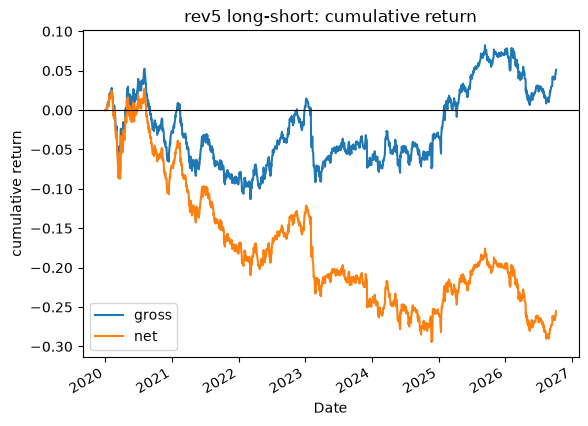

In [14]:
import matplotlib.pyplot as plt

BPS_COST = 5 # transiction cost

def backtest(w, returns, cost_bps=BPS_COST, delay=1):
    pos      = w.shift(delay + 1).fillna(0)
    gross    = (pos * returns.fillna(0)).sum(axis=1)
    turnover = (pos - pos.shift(1)).abs().sum(axis=1)
    return pd.DataFrame({"gross": gross,
                         "net": gross - turnover * cost_bps / 1e4,
                         "turnover": turnover})

def stats(pnl):
    ann_ret, ann_vol = pnl.mean() * 252, pnl.std() * np.sqrt(252)
    cum = pnl.cumsum()
    return pd.Series({"ann_return": ann_ret, "ann_vol": ann_vol,
                      "sharpe": ann_ret / ann_vol,
                      "max_drawdown": (cum - cum.cummax()).min()})

bt = backtest(processed["rev5"], returns)
print("gross:", stats(bt["gross"]).round(3).to_dict())
print("net:  ", stats(bt["net"]).round(3).to_dict())
print("turnover/day:", bt["turnover"].mean().round(3))

bt[["gross", "net"]].cumsum().plot(title="rev5 long-short: cumulative return")
plt.axhline(0, lw=0.8, color="black")
plt.ylabel("cumulative return")
plt.show()


rev5
gross: {'ann_return': 0.008, 'ann_vol': 0.072, 'sharpe': 0.107, 'max_drawdown': -0.166}
net:   {'ann_return': -0.038, 'ann_vol': 0.072, 'sharpe': -0.533, 'max_drawdown': -0.322}
turnover/day: 0.365


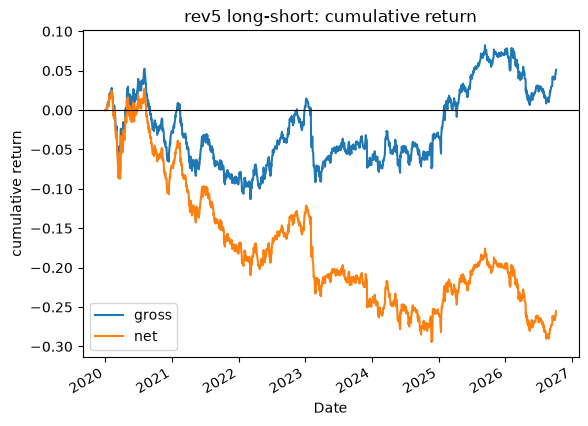

mom12_1
gross: {'ann_return': 0.017, 'ann_vol': 0.062, 'sharpe': 0.272, 'max_drawdown': -0.145}
net:   {'ann_return': 0.012, 'ann_vol': 0.062, 'sharpe': 0.198, 'max_drawdown': -0.15}
turnover/day: 0.037


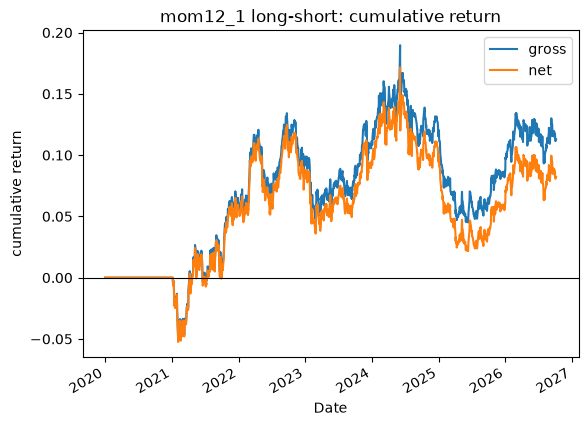

lowvol
gross: {'ann_return': -0.059, 'ann_vol': 0.075, 'sharpe': -0.79, 'max_drawdown': -0.509}
net:   {'ann_return': -0.071, 'ann_vol': 0.075, 'sharpe': -0.948, 'max_drawdown': -0.58}
turnover/day: 0.093


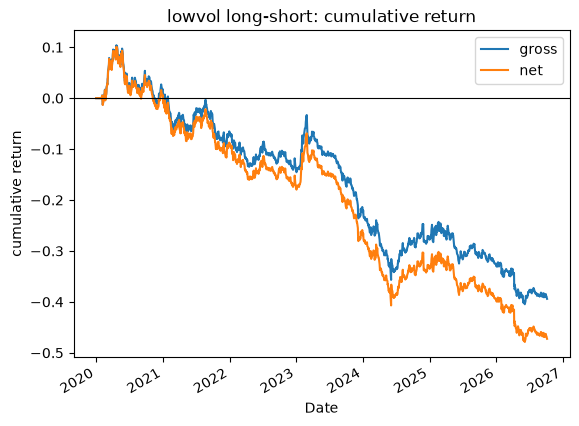

volshock
gross: {'ann_return': 0.023, 'ann_vol': 0.06, 'sharpe': 0.393, 'max_drawdown': -0.217}
net:   {'ann_return': -0.051, 'ann_vol': 0.06, 'sharpe': -0.85, 'max_drawdown': -0.398}
turnover/day: 0.589


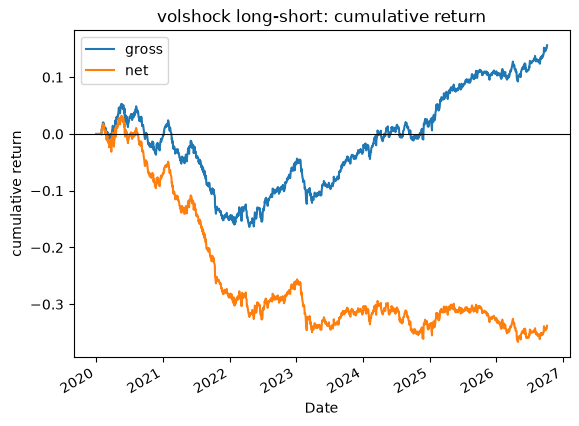

near_high
gross: {'ann_return': -0.007, 'ann_vol': 0.06, 'sharpe': -0.109, 'max_drawdown': -0.147}
net:   {'ann_return': -0.016, 'ann_vol': 0.06, 'sharpe': -0.269, 'max_drawdown': -0.175}
turnover/day: 0.077


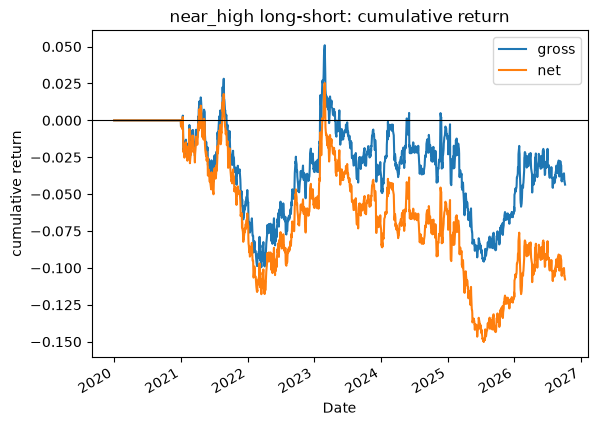

In [15]:
for alpha in processed.keys():
    bt = backtest(processed[alpha], returns)
    print(alpha)
    print("gross:", stats(bt["gross"]).round(3).to_dict())
    print("net:  ", stats(bt["net"]).round(3).to_dict())
    print("turnover/day:", bt["turnover"].mean().round(3))
    bt[["gross", "net"]].cumsum().plot(title=f"{alpha} long-short: cumulative return")
    plt.axhline(0, lw=0.8, color="black")
    plt.ylabel("cumulative return")
    plt.show()

In [10]:
BOOK = 2.0e7          
CAPITAL = BOOK / 2    

def evaluate(bt, book=BOOK, col="net"):
    capital = book / 2
    r = bt[col]                                   
    rows = {}

    for year, idx in list(r.groupby(r.index.year).groups.items()) + [("all", r.index)]:
        pnl_r  = r.loc[idx]                       
        turn   = bt["turnover"].loc[idx]
        n      = len(pnl_r)

        pnl_cur = pnl_r * book                    
        ret     = pnl_r * book / capital          
        cum     = ret.cumsum()
        traded  = (turn * book).sum()

        rows[year] = {
            "book_size":   book,
            "pnl":         pnl_cur.sum(),
            "ann_return":  ret.mean() * 252,
            "info_ratio":  ret.mean() / ret.std() * np.sqrt(252),
            "max_dd":      -(cum - cum.cummax()).min(),
            "pct_days":    (pnl_r > 0).mean(),
            "turnover":    turn.mean(),
            "profit_per_$": pnl_cur.sum() / traded * 100,   
        }

    out = pd.DataFrame(rows).T
    return out


bt  = backtest(processed["rev5"], returns)
tbl = evaluate(bt)

fmt = tbl.copy()
for c in ["ann_return", "max_dd", "pct_days", "turnover"]:
    fmt[c] = (tbl[c] * 100).round(2).astype(str) + "%"
fmt["book_size"]    = tbl["book_size"].map("{:.1E}".format)
fmt["pnl"]          = tbl["pnl"].map("{:.2E}".format)
fmt["info_ratio"]   = tbl["info_ratio"].round(2)
fmt["profit_per_$"] = tbl["profit_per_$"].round(2).astype(str) + "¢"
print(fmt.to_string())


     book_size        pnl ann_return  info_ratio   max_dd pct_days turnover profit_per_$
2020   2.0E+07  -3.16E+06    -31.72%       -1.54   41.11%   47.41%   34.89%       -0.18¢
2021   2.0E+07  -3.96E+06    -40.27%       -3.08   44.76%   42.34%   35.92%       -0.22¢
2022   2.0E+07  -8.68E+05     -8.82%       -0.68   15.29%   46.77%   37.47%       -0.05¢
2023   2.0E+07  -4.13E+06    -42.47%       -3.03   43.27%   41.22%   36.89%       -0.23¢
2024   2.0E+07  -2.05E+06    -20.98%       -1.47   27.58%   46.75%   36.73%       -0.11¢
2025   2.0E+07  -6.34E+05     -6.42%       -0.57   12.34%   44.58%   37.26%       -0.03¢
2026   2.0E+07  -2.56E+06    -33.56%       -2.85   30.62%   40.62%   36.24%       -0.18¢
all    2.0E+07  -1.74E+07    -26.05%       -1.81  181.44%   44.37%   36.49%       -0.14¢
